# Khám phá dữ liệu `cell_features.parquet`

Notebook này mô tả dữ liệu không gian đã tạo cho khu vực `29_3`.


```text
Đọc dữ liệu → xem cấu trúc → kiểm tra chất lượng
→ phân tích POI → khoảng cách nearest → mạng đường
→ tương quan → bản đồ phân bố không gian
```



In [12]:
from pathlib import Path
import re
import seaborn as sns

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


def find_root(start=Path.cwd()):
    for path in [start, *start.parents]:
        if (path / "pyproject.toml").exists():
            return path
    raise FileNotFoundError("Không tìm thấy project root")


ROOT = find_root()
DATA_PATH = ROOT / "data/processed/hanoi/cell_features.parquet"
features = gpd.read_parquet(DATA_PATH)

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

print("File:", DATA_PATH)
print(f"Kích thước: {features.shape[0]:,} cell × {features.shape[1]} cột")
print("CRS:", features.crs)

File: d:\ADY201_FA26\data\processed\hanoi\cell_features.parquet
Kích thước: 85,249 cell × 135 cột
CRS: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "ProjectedCRS", "name": "WGS 84 / UTM zone 48N", "base_crs": {"type": "GeographicCRS", "name": "WGS 84", "datum_ensemble": {"name": "World Geodetic System 1984 ensemble", "members": [{"name": "World Geodetic System 1984 (Transit)"}, {"name": "World Geodetic System 1984 (G730)"}, {"name": "World Geodetic System 1984 (G873)"}, {"name": "World Geodetic System 1984 (G1150)"}, {"name": "World Geodetic System 1984 (G1674)"}, {"name": "World Geodetic System 1984 (G1762)"}, {"name": "World Geodetic System 1984 (G2139)"}, {"name": "World Geodetic System 1984 (G2296)"}], "ellipsoid": {"name": "WGS 84", "semi_major_axis": 6378137, "inverse_flattening": 298.257223563}, "accuracy": "2.0", "id": {"authority": "EPSG", "code": 6326}}, "coordinate_system": {"subtype": "ellipsoidal", "axis": [{"name": "Geodetic latitude", "abbrev

## 1. Tổng quan dữ liệu



In [13]:
columns = features.columns

radius_suffixes = (
    "_count_100m", "_count_200m", "_count_500m",
    "_count_1000m", "_count_2000m", "_count_5000m",
)

cell_columns = ["cell_id", "cell_area_km2", "geometry", "points"]

groups = {
    "Thông tin cell": [col for col in cell_columns if col in columns],
    "POI trực tiếp": [col for col in columns if col.endswith("_count")],
    "POI theo bán kính": [col for col in columns if col.endswith(radius_suffixes)],
    "Khoảng cách nearest": [col for col in columns if col.startswith("nearest_")],
    "Mạng đường": [col for col in columns if col.startswith("road_")],
}

rows = []
for name, group_columns in groups.items():
    rows.append({
        "Nhóm cột": name,
        "Số cột": len(group_columns),
        "Ví dụ": ", ".join(group_columns[:3]),
    })

group_summary = pd.DataFrame(rows)
display(group_summary)


,Nhóm cột,Số cột,Ví dụ
0,Thông tin cell,4,"cell_id, cell_area_km2, geometry"
1,POI trực tiếp,14,"poi_count, arts_and_entertainment_count, commu..."
2,POI theo bán kính,78,"arts_and_entertainment_count_100m, arts_and_en..."
3,Khoảng cách nearest,35,"nearest_arts_and_entertainment_m, nearest_comm..."
4,Mạng đường,4,"road_length_500m_km, road_density_500m_km_per_..."


## 2. Kiểm tra chất lượng dữ liệu

In [14]:
numeric = features.select_dtypes(include="number")

quality = pd.Series(
    {
        "Cell trùng cell_id": features["cell_id"].duplicated().sum(),
        "Cell thiếu cell_id": features["cell_id"].isna().sum(),
        "Geometry bị thiếu": features.geometry.isna().sum(),
        "Geometry không hợp lệ": (~features.geometry.is_valid).sum(),
        "Giá trị numeric bị thiếu": numeric.isna().sum().sum(),
        "Giá trị numeric vô hạn": np.isinf(numeric).sum().sum(),
        "Giá trị numeric âm": (numeric < 0).sum().sum(),
    },
    name="số lượng",
)

display(quality.to_frame())

missing = features.isna().sum()
missing = missing[missing > 0]

if not missing.empty:
    display(missing.to_frame("Số giá trị thiếu"))
else:
    print("✓ Không có giá trị thiếu trong dataset.")
    

,số lượng
Cell trùng cell_id,0
Cell thiếu cell_id,0
Geometry bị thiếu,0
Geometry không hợp lệ,0
Giá trị numeric bị thiếu,0
Giá trị numeric vô hạn,0
Giá trị numeric âm,0


✓ Không có giá trị thiếu trong dataset.


## 3. POI trong phạm vi 200m




,mean,median,q90,max,zero_%
Đồ ăn,2.04,0.00,1.00,569,83.72
Dịch vụ,2.70,0.00,3.00,460,68.05
Mua sắm,3.51,0.00,3.00,614,76.53
Giáo dục,0.61,0.00,1.00,99,87.25
Y tế,0.37,0.00,0.00,73,90.46
Giao thông,0.39,0.00,0.00,147,91.06


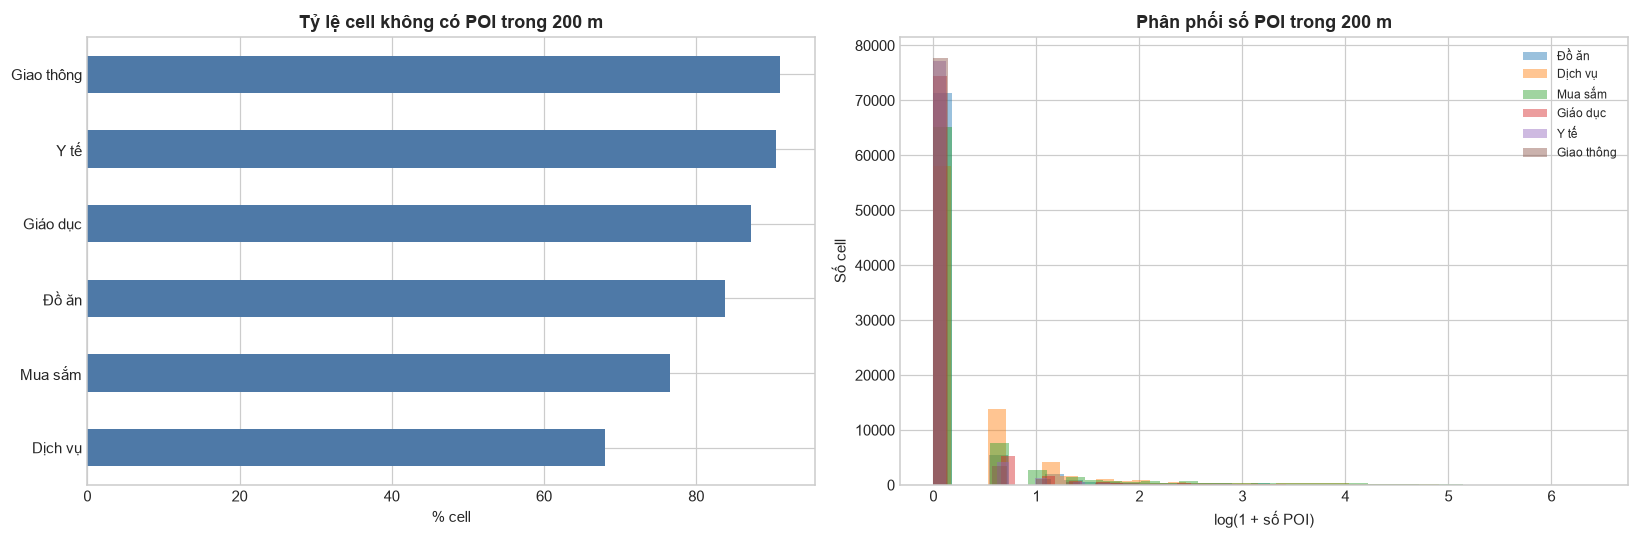

In [15]:
poi_200m = {
    "Đồ ăn": "food_and_drink_count_200m",
    "Dịch vụ": "services_and_business_count_200m",
    "Mua sắm": "shopping_count_200m",
    "Giáo dục": "education_count_200m",
    "Y tế": "health_care_count_200m",
    "Giao thông": "travel_and_transportation_count_200m",
}

poi_summary = pd.DataFrame(
    {
        "mean": {name: features[column].mean() for name, column in poi_200m.items()},
        "median": {name: features[column].median() for name, column in poi_200m.items()},
        "q90": {name: features[column].quantile(0.90) for name, column in poi_200m.items()},
        "max": {name: features[column].max() for name, column in poi_200m.items()},
        "zero_%": {name: 100 * (features[column] == 0).mean() for name, column in poi_200m.items()},
    }
)
display(poi_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
poi_summary["zero_%"].sort_values().plot.barh(ax=axes[0], color="#4E79A7")
axes[0].set(title="Tỷ lệ cell không có POI trong 200 m", xlabel="% cell")

for name, column in poi_200m.items():
    axes[1].hist(
        np.log1p(features[column]), bins=35, alpha=0.45, label=name
    )
axes[1].set(
    title="Phân phối số POI trong 200 m",
    xlabel="log(1 + số POI)",
    ylabel="Số cell",
)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4. Khoảng cách tới tiện ích gần nhất

Khoảng cách được đổi sang kilomet để dễ đọc. Boxplot không hiển thị outlier nhằm tập trung vào phần lớn cell.

,mean,25%,50%,75%,90%,max
Bệnh viện,2.48,1.04,1.93,3.27,5.39,11.74
Trường học,1.67,0.79,1.45,2.30,3.21,8.38
Thực phẩm,1.78,0.72,1.38,2.36,3.77,11.02
Công viên,4.32,1.72,3.48,6.37,8.95,18.08
Trạm xe buýt,10.12,4.92,9.08,14.31,19.11,33.71
Nhà thuốc,1.91,0.87,1.58,2.56,3.79,9.74


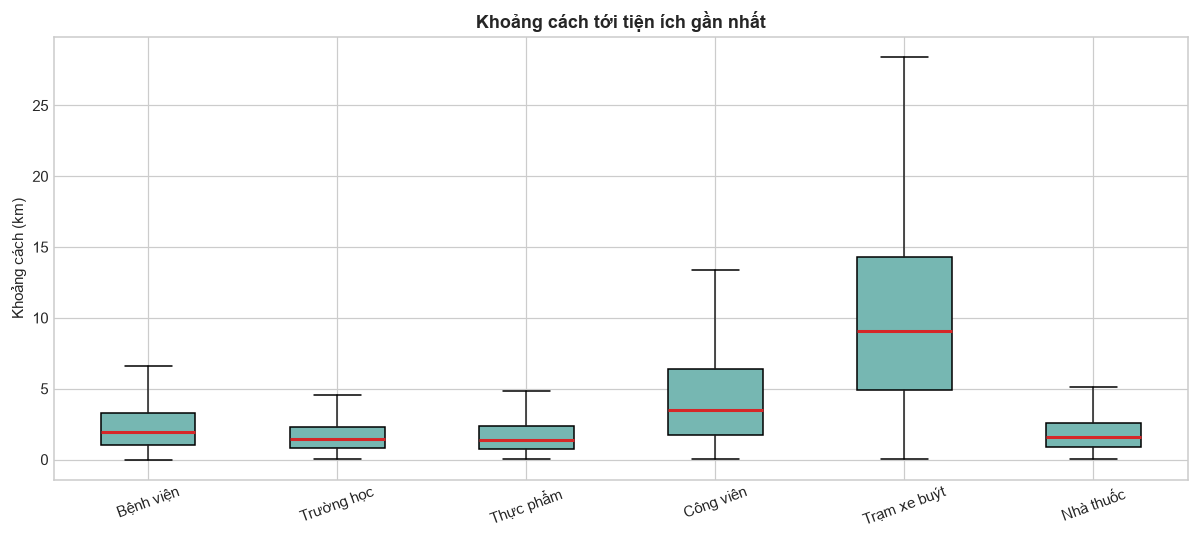

In [16]:
nearest = {
    "Bệnh viện": "nearest_hospital_m",
    "Trường học": "nearest_school_m",
    "Thực phẩm": "nearest_grocery_store_m",
    "Công viên": "nearest_park_m",
    "Trạm xe buýt": "nearest_bus_station_m",
    "Nhà thuốc": "nearest_pharmacy_m",
}

nearest_km = pd.DataFrame()
for name, column in nearest.items():
    nearest_km[name] = features[column] / 1000

summary = nearest_km.describe(percentiles=[0.25, 0.50, 0.75, 0.90]).T
display(summary[["mean", "25%", "50%", "75%", "90%", "max"]].round(2))

nearest_km.boxplot(
    figsize=(11, 5),
    rot=20,
    showfliers=False,
    patch_artist=True,
    boxprops={"facecolor": "#76B7B2"},
    medianprops={"color": "#D62728", "linewidth": 2},
)
plt.title("Khoảng cách tới tiện ích gần nhất")
plt.ylabel("Khoảng cách (km)")
plt.tight_layout()
plt.show()

## 5. Mạng đường quanh cell

,mean,std,25%,50%,75%,max
500 m,9.70,7.04,5.49,8.46,11.76,56.18
1.000 m,9.73,6.38,6.27,8.55,11.09,49.50


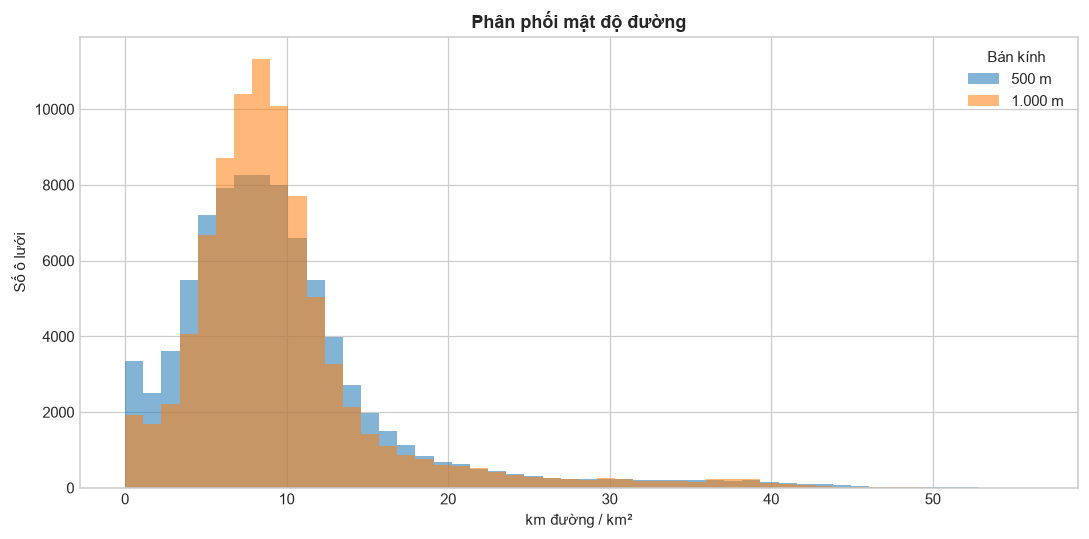

In [17]:
road_columns = {
    "500 m": "road_density_500m_km_per_km2",
    "1.000 m": "road_density_1000m_km_per_km2",
}

roads = pd.DataFrame()

for label, column in road_columns.items():
    roads[label] = features[column]

summary = roads.describe().T
display(summary[["mean", "std", "25%", "50%", "75%", "max"]].round(2))

ax = roads.plot.hist(bins=50, alpha=0.55, figsize=(10, 5))
ax.set(
    title="Phân phối mật độ đường",
    xlabel="km đường / km²",
    ylabel="Số ô lưới",
)
ax.legend(title="Bán kính")
plt.tight_layout()
plt.show()

## 6. Tương quan giữa các feature chính

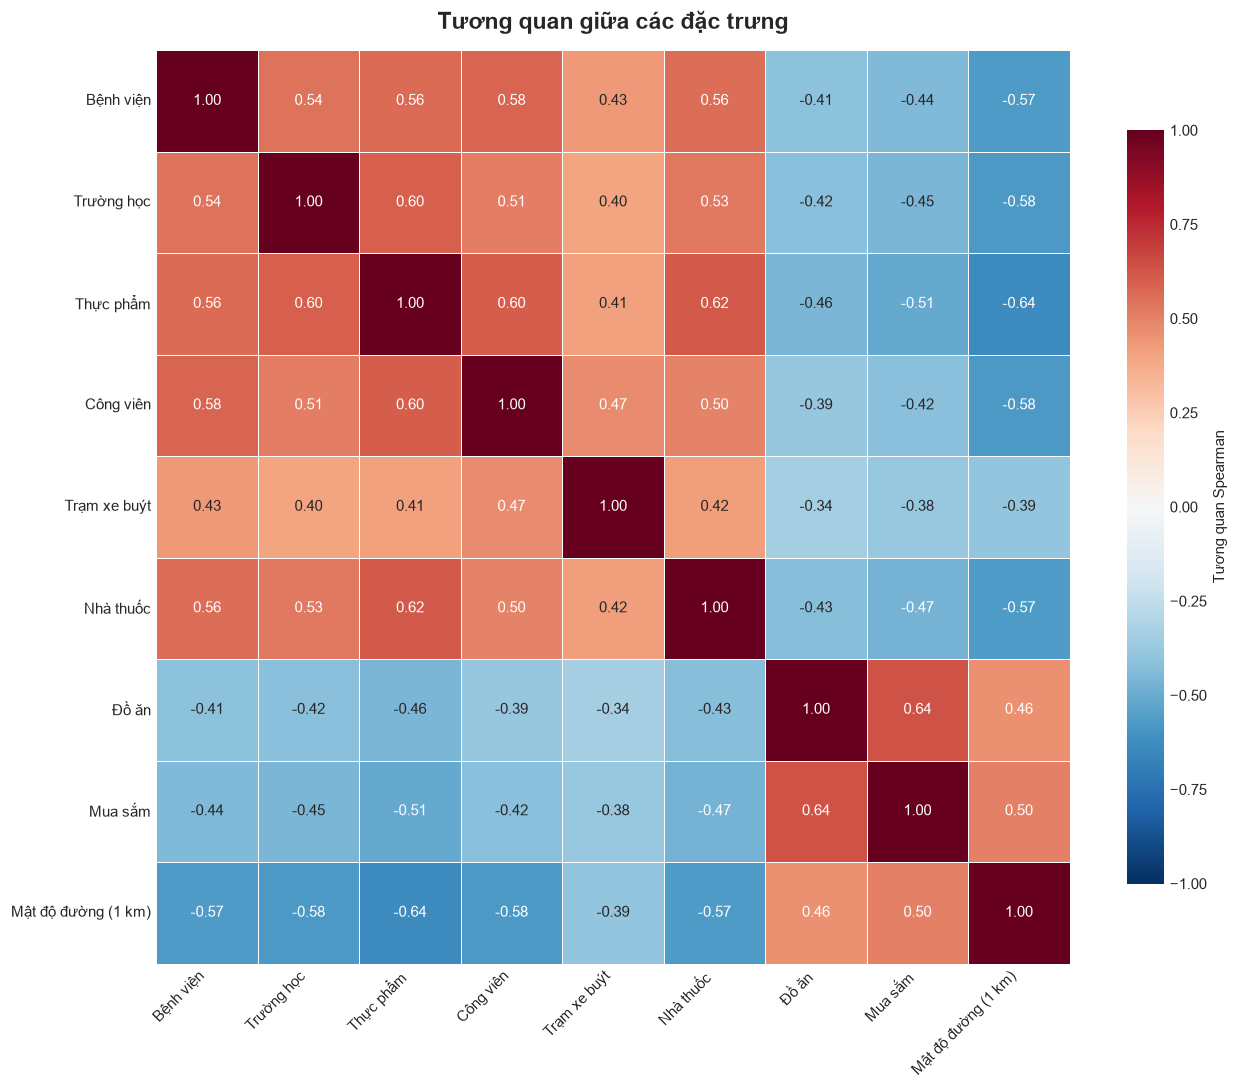

In [18]:
correlation_features = nearest_km.copy()
correlation_features["Đồ ăn"] = features["food_and_drink_count_200m"]
correlation_features["Mua sắm"] = features["shopping_count_200m"]
correlation_features["Mật độ đường (1 km)"] = features["road_density_1000m_km_per_km2"]

corr = correlation_features.corr(method="spearman")
short_labels = corr.columns.tolist()
plt.figure(figsize=(12, 10))

ax = sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    linecolor="white",
    xticklabels=short_labels,
    yticklabels=short_labels,
    cbar_kws={"label": "Tương quan Spearman", "shrink": 0.8},
)

ax.set_title("Tương quan giữa các đặc trưng", fontsize=15, fontweight="bold", pad=14)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 7. Phân bố không gian ở trung tâm Hà Nội



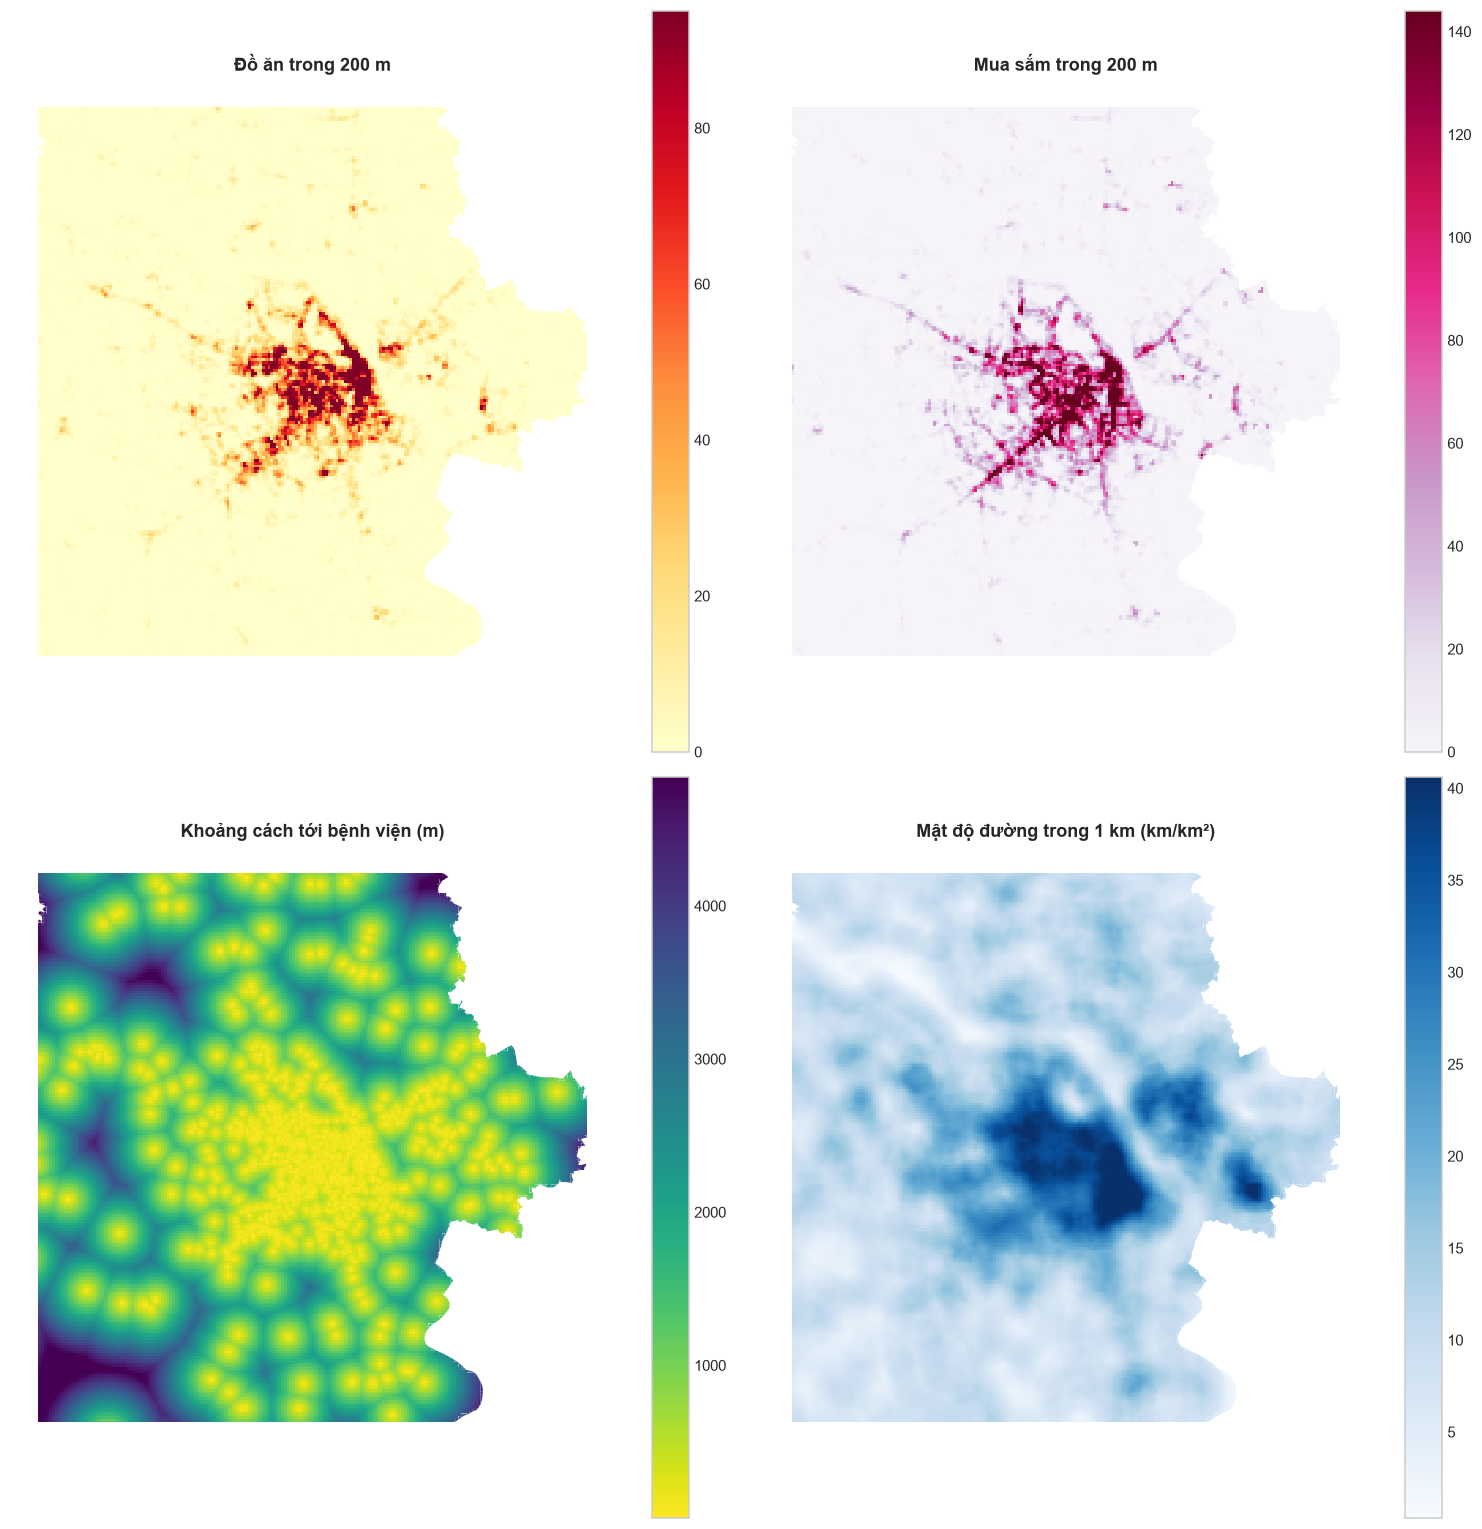

In [19]:
xmin, xmax, ymin, ymax = 565_000, 605_000, 2_305_000, 2_345_000
central = features.cx[xmin:xmax, ymin:ymax].copy()

map_specs = [
    ("food_and_drink_count_200m", "YlOrRd", "Đồ ăn trong 200 m"),
    ("shopping_count_200m", "PuRd", "Mua sắm trong 200 m"),
    ("nearest_hospital_m", "viridis_r", "Khoảng cách tới bệnh viện (m)"),
    ("road_density_1000m_km_per_km2", "Blues", "Mật độ đường trong 1 km (km/km²)"),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 14))
for (column, cmap, title), ax in zip(map_specs, axes.flat):
    plot_column = f"plot_{column}"
    central[plot_column] = central[column].clip(
        upper=central[column].quantile(0.99)
    )
    central.plot(
        column=plot_column, cmap=cmap, legend=True, linewidth=0, ax=ax
    )
    ax.set_title(title)
    ax.set_axis_off()

plt.tight_layout()
plt.show()
